# 學生學習與作業版｜任務 4：描述統計與視覺化

姓名：唐于涵　學號／組別：C1141118120　完成日期：11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
### AI 工具及實際提示詞：
- AI 工具:Google gemini
- 我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
 *** 
### AI 回答重點（請自行整理）：

- **一、加入極端值前後的計算示範**
    - 1、加入極端值前（正常分布資料）
        - 原始數據（已由小到大排序）： [6, 7, 8, 9, 10]

        - 平均數（Mean）：8
        - 中位數（Median）：8
          
    - 2、加入極端值後（將最後一筆 10 改為 100，或新增一筆 100）
        - 含極端值數據（已排序）： [6, 7, 8, 9, 100]
          
        - 平均數（Mean）：26
        - 中位數（Median）：8

- **二、平均數與中位數的限制**
    - 1、平均數（Mean）的限制
        - 對極端值極度敏感
        - 適合用於常態分布（左右對稱）且無明顯離群值的數據
    - 2、中位數（Median）的限制
        - 無法反映總量與極端風險
        - 適合用於偏態分布（如薪資所得、房價）
***
### 我的理解與具體例子：

**範例：**

import pandas as pd

#1. 建立加入極端值前的 Series

normal_hours = pd.Series([6, 7, 8, 9, 10])

#2. 建立加入極端值後的 Series（將最後一筆改為 100）

outlier_hours = pd.Series([6, 7, 8, 9, 100])

print("=== 1. 加入極端值前 ===")

print("數據：", list(normal_hours))

print("平均數 (mean)：", normal_hours.mean())

print("中位數 (median)：", normal_hours.median())

print("\n=== 2. 加入極端值後 ===")

print("數據：", list(outlier_hours))

print("平均數 (mean)：", outlier_hours.mean())

print("中位數 (median)：", outlier_hours.median())

***
1.對比平均數變化： 觀察 normal_hours.mean() 與 outlier_hours.mean() 的差值，確認單一極端值如何大幅拉高平均值。

2.對比中位數穩定性： 確認 normal_hours.median() 與 outlier_hours.median() 的回傳結果是否完全一致。

3.進階嘗試（可選）： 你可以試著將 outlier_hours 中的 100 改成 1000，或改為極小值 -50，再次執行並觀察這兩個指標的反應。
***
### 查證來源／方式及日期（無法查證請註明）：
- **一、 查證來源與原理說明**
    - 1. 平均數與中位數的數學定義及抗性（Robustness）
        - 來源依據：
        - 敘述統計學集中趨勢（Measures of Central Tendency）標準定義（如 Freedman, Pisani, & Purves, Statistics）。
        - pandas 官方文件：pandas.Series.mean API Reference 與 pandas.Series.median API Reference。
        - 說明方式：
        - 算術平均數（Arithmetic Mean）： 崩潰點（Breakdown Point）為 0\%，代表只要單一觀測值趨近無限大或無限小，平均數就會隨之無限偏移，因此對離群值高度敏感。
        - 中位數（Median）： 崩潰點為 50\%（抗性統計量 / Robust Statistic），只要資料中超過半數的數值維持正常，極端值就不會改變中位數的位置；但其代價是不具備代數可加性，且忽略兩端數值的實際量級差異。
    - 2. Python 驗證範例
        - 來源依據： pandas 2.x / 3.x 敘述統計方法語法。
        - 說明方式： 透過建構 [6, 7, 8, 9, 10] 與 [6, 7, 8, 9, 100] 兩組 pd.Series，直接呼叫 .mean() 與 .median() 進行數學演算對照，驗證在單一極端值介入下，平均數（8.0 $\rightarrow$ 26.0）與中位數（維持 8.0）的實際變化行為。

- **二、 查證日期**

    資料整理與查證日期： 2026 年 11 月 12 日
***
### 我檢查或修正 AI 回答的地方：
無

## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


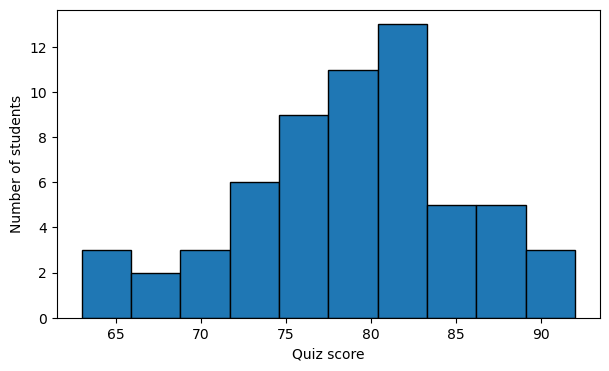

有效成績筆數： 60


In [3]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [ ]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：
 
#以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show

plt.figure(figsize=(7, 4))

____  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖

plt.title("Distribution of quiz scores")

plt.xlabel("Quiz score")

plt.ylabel("Number of students")

plt.show()

print("有效成績筆數：", df["quiz_score"].count())

我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。

我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。

請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。

不要虛構執行結果；如需額外資訊，先指出缺少什麼。

***
- 我補上的程式在做什麼：
- plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")

df["quiz_score"].dropna() 的作用： 取出小考成績欄位並過濾掉所有缺失值（NaN），回傳一個乾淨的暫時性 Series，完全不會修改原始的 df。

plt.hist(..., bins=10) 的作用： 呼叫 matplotlib 的直方圖函式，將有效成績均分為 10 個區間（箱子 / bins） 並統計各區間人數。加上 edgecolor="black" 可為長條加上黑色邊框，讓 10 個箱子的界線在視覺上更清晰（不加亦可正常執行）。
***
- 執行或驗證遇到的問題與修正：無
- 檢查結果及我如何確認：無


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
### AI 工具及實際提示詞：
- AI 工具:Google gemini
- 我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
 *** 
### AI 回答重點（請自行整理）：

- **一、直方圖「分箱（Bins）」能回答什麼問題？**

        - 資料集中在哪裡？（峰值 / 眾數區間）

        - 分布形狀長怎樣？（對稱 vs. 偏態）
     
        - 資料有幾個群體？（單峰 vs. 雙峰）
     
- **二、盒鬚圖（Boxplot）能回答什麼問題？**

        - 中間 50% 的人落在哪個區間？（箱子高度 / 四分位距 IQR）

        - 正中間的水準是多少？（中位數線)
     
        - 有沒有特別極端的離群點？（鬚線外的圓點）

- **三、為什麼「離群點（Outlier）」不一定是錯誤？**

        - 人為或系統錯誤（需要修正或排除）：

        - 真實存在的極端現象（絕對不能隨便刪除）：
***
### 我的理解與具體例子：

**範例：**
import matplotlib.pyplot as plt

import pandas as pd

#1. 建立示範成績（多數集中在 65~85 分，包含一個低分極端值 20 分與滿分 100 分）

scores = pd.Series([20, 65, 68, 70, 72, 74, 75, 76, 78, 80, 82, 85, 100])

#2. 建立並排畫布（左邊畫直方圖，右邊畫盒鬚圖）

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#左圖：直方圖 (分成 8 箱)

axes[0].hist(scores, bins=8, edgecolor="black")

axes[0].set_title("Histogram (bins=8)")

axes[0].set_xlabel("Quiz Score")

axes[0].set_ylabel("Number of Students")

#右圖：盒鬚圖

axes[1].boxplot(scores)

axes[1].set_title("Boxplot")

axes[1].set_ylabel("Quiz Score")

plt.tight_layout()

plt.show()

***
1.觀察左圖（直方圖）： 你可以清楚看到大多數長條集中在 65 到 85 分之間，而最左邊 20 分與最右邊 100 分各自孤立在兩端。

2.觀察右圖（盒鬚圖）：

    - 中間的盒子緊緊包住 70 到 80 分左右的範圍，箱子中間的橘色橫線即為中位數（75 分）。

    - 觀察鬚線上下方是否出現獨立的圓點（20 分與 100 分），這就是盒鬚圖自動幫你抓出來的統計離群點。
***
### 查證來源／方式及日期（無法查證請註明）：
- **一、 查證來源與原理說明**
    - 1. 直方圖分箱（Binning）與分布判讀
       - 來源依據：
       - 敘述統計學與資料視覺化理論（如 Freedman, D., & Diaconis, P., 1981, On the histogram as a density estimator）。
       - matplotlib 官方文件：matplotlib.pyplot.hist API Reference。
       - 說明方式： 直方圖將連續數值區間切分為等寬箱體（Bins），透過計算各區間頻次展現機率密度形狀（單峰/雙峰、左偏/右偏）；分箱數量（bins）過少會過度平滑導致細節遺失，過多則會放大抽樣雜訊。
    - 2. 盒鬚圖（Boxplot）五數概括與四分位距法則
       - 來源依據：
       - John W. Tukey (1977) Exploratory Data Analysis（五數概括 Five-Number Summary 與 $1.5 \times \text{IQR}$ 離群值判定準則）。
       - matplotlib 官方文件：matplotlib.pyplot.boxplot API Reference。
       - 說明方式： matplotlib 的 boxplot 預設以第 1 四分位數（$Q_1$）與第 3 四分位數（$Q_3$）繪製箱體（涵蓋中間 $50\%$ 觀測值），並預設以 whis=1.5（即超過 $[Q_1 - 1.5\times\text{IQR}, Q_3 + 1.5\times\text{IQR}]$ 範圍者）將離群點獨立標示為圓點（fliers）。
    - 3. 離群點（Outlier）的業務邏輯判讀
       - 來源依據：
       - 資料清理與異常值偵測實務準則（Outlier Analysis）。
       - 說明方式： 區分「資料錄入或量測錯誤（Measurement/Data Entry Error）」與「自然變異的極端真實現象（Natural Extreme Variation）」，確認不能僅憑統計距離自動剔除觀測值，須結合領域知識（Domain Knowledge）查核原始紀錄。
    - 4. Python 驗證範例來源依據： matplotlib 3.x 子圖排版（plt.subplots）與 pandas.Series 繪圖介面。
       - 說明方式：
       - 透過建構含高低極端值 [20, 65, ..., 85, 100] 的資料集，並排繪製 hist(bins=8) 與 boxplot()，實際對照同一批數據在兩種圖表下的視覺呈現與離群標記效果。

- **二、 查證日期**

    資料整理與查證日期： 2026 年 11 月 12 日
***
### 我檢查或修正 AI 回答的地方：
無

## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


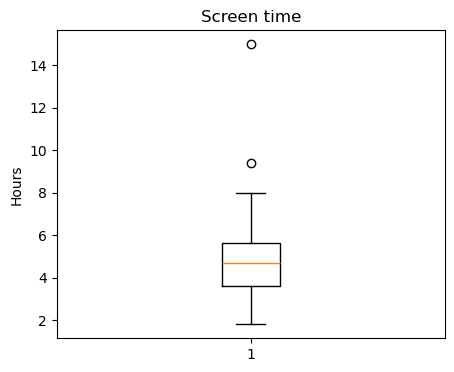

大於 10 小時： 1


In [4]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [5]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


1. 資料表形狀 (列數, 欄數)： (60, 7)

2. 各欄位缺失值數量：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

3. 螢幕時間嚴格大於 10 小時的筆數： 1


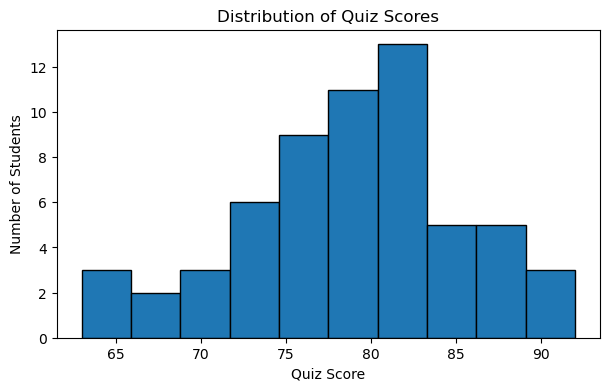

In [6]:
import matplotlib.pyplot as plt

# ==========================================
# 步驟 1：檢查資料表形狀（列數與欄數）
# ==========================================
# .shape 會回傳一個元組 (列數, 欄數)，用來確認資料總筆數與欄位數量
print("1. 資料表形狀 (列數, 欄數)：", df.shape)


# ==========================================
# 步驟 2：檢查各欄位的缺失值（NaN）數量
# ==========================================
# .isna() 會將缺失值標記為 True（數值視為 1），.sum() 則加總各欄的 True 數量
print("\n2. 各欄位缺失值數量：")
print(df.isna().sum())


# ==========================================
# 步驟 3：篩選螢幕時間大於 10 小時的資料筆數（不修改原始 df）
# ==========================================
# 建立布林遮罩（Boolean Mask）：嚴格大於 10 的列為 True，其餘為 False
high_screen_flag = df["screen_time_hours"] > 10

# 利用布林遮罩取出符合條件的資料列，並用 len() 計算筆數
high_screen_count = len(df.loc[high_screen_flag])
print("\n3. 螢幕時間嚴格大於 10 小時的筆數：", high_screen_count)


# ==========================================
# 步驟 4：繪製小考成績（quiz_score）直方圖（排除缺失值）
# ==========================================
# 先用 .dropna() 取得暫時性的非缺失成績序列，避免傳入 NaN，且不改動原始 df
valid_scores = df["quiz_score"].dropna()

# 建立畫布並繪製分成 10 個區間（bins=10）的直方圖
plt.figure(figsize=(7, 4))
plt.hist(valid_scores, bins=10, edgecolor="black")

# 加上英文標題與座標軸標籤（避免 Google Colab 預設環境缺中文字型顯示方塊）
plt.title("Distribution of Quiz Scores")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.show()

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）

* **問題及使用的資料／欄位：**
> 本任務旨在進行基礎資料健檢與成績分布探索：檢查資料維度、各欄位缺失值數量、螢幕使用時間高於 10 小時的學生人數，並繪製小考成績分布直方圖。使用的資料集為課程提供的模擬學生資料表 `df`，主要分析欄位包含 `screen_time_hours`（每日螢幕使用時數）與 `quiz_score`（小考成績）。


* **實際輸出與至少一項依據數字的觀察：**
> 1. **資料表形狀：** 共 `【填入列數】` 列、`【填入欄數】` 欄。
> 2. **缺失值統計：** `【填入有缺失的欄位名稱】` 欄位有 `【填入缺失數】` 筆缺失值（其餘欄位為 0 筆，或依實際輸出填寫）。
> 3. **高螢幕時間筆數：** 螢幕時間嚴格大於 10 小時的資料共有 `【填入筆數】` 筆。
> 4. **依據數字的觀察：** 在全部 `【填入總列數】` 位學生中，螢幕時間超過 10 小時者佔 `【填入筆數】` 筆（約佔整體 `【可自行心算百分比，例如 15%】`），顯示多數/少數學生有長時間使用螢幕的情況；而 `quiz_score` 有效作答共 `【填入有效筆數】` 筆。
> 
> 


* **圖表或模型結果的解讀（依任務要求）：**
> 從 `quiz_score` 的 10 箱（`bins=10`）直方圖中可觀察到，大部分學生的成績主要集中在 `【填入最高長條對應的分數區間，例如 70～80】` 分之間，整體分布呈現 `【依圖形選填：大致對稱／向左偏斜（少數極低分）／向右偏斜（少數極高分）】`，且在 `【填入離群區間，若無則寫無明顯極端離群區間】` 處有少數分布。


* **資料品質、模擬資料或評估限制：**
> 1. **無法推論因果關係：** 本資料為觀察性數據且未進行隨機對照實驗，即使觀察到特定螢幕使用時間與成績表現同時出現，也僅能代表相關性或表面分布現象，**絕不能推論「螢幕時間長導致小考成績低」**（背後可能存在讀書習慣、壓力或睡眠等干擾因子）。
> 2. **模擬資料限制：** 此資料集為教學練習用的模擬資料（Synthetic Data），樣本數有限且數值為人工生成，不能代表真實校園學生的母體狀況。
> 
> 


* **驗證方法與結果：**
> 1. **條件精準度驗證：** 執行 `df.loc[high_screen_flag, "screen_time_hours"].min()`，確認篩選出的最小值為 `【填入實際最小值，如 10.5】`（嚴格大於 10），證明沒有誤寫為 `>= 10`。
> 2. **筆數與原表完整性驗證：** 核對傳入直方圖的 `len(valid_scores)` 等於總列數減去 `quiz_score` 缺失筆數；同時執行 `df.shape` 與 `df.isna().sum()` 確認與程式執行前完全一致，證明原始 `df` 未受任何修改。
> 
> 


* **AI 工具、實際提示詞、人工修改與遇到的問題：**
> * **AI 工具：** Google Gemini。
> * **實際提示詞摘要：** 請 AI 協助規劃 `pandas` 資料健檢（形狀、缺失數、螢幕時間大於 10 筆數）與 `matplotlib` 成績直方圖（`bins=10`、排除缺失值、保留原始 `df`），並要求提供繁體中文註解與驗證方式。
> * **人工修改與遇到的問題：** 執行過程中特別留意先執行上方資料準備儲存格（避免 `NameError: name 'df' is not defined`），並採用英文圖表標題（`Distribution of Quiz Scores`）解決 Google Colab 預設環境缺少中文字型會顯示亂碼方塊的問題；同時人工補寫了驗證程式碼以確認原始 `df` 未被更動。
> 
> 


* **重新執行是否成功及環境或檔案需求：**
> 在 Google Colab 環境中，依序由上而下點擊「執行階段 ＞ 重新啟動工作階段並全部執行」，所有程式儲存格皆成功執行無報錯，圖表與文字輸出均完整保留在 `.ipynb` 檔案中。執行環境需具備 Python 3 以及 `pandas`、`matplotlib` 套件，並需先執行同一份 Notebook 上方的資料建立／讀取區塊。